# Módulo 7 — Métodos de Fourier I: da função característica à fórmula de Lewis

## Introdução

Muitos modelos realistas não têm uma fórmula fechada para o preço das opções, mas têm uma fórmula fechada para outra coisa: a **função característica** do log-preço, a transformada de Fourier de sua distribuição. É o caso dos modelos com saltos e de volatilidade estocástica usados no restante do livro.

A ideia dos métodos de Fourier é precificar a partir dessa transformada. O preço de uma call é uma integral do pagamento contra a densidade do ativo; pela fórmula de Parseval, ele pode ser escrito como uma integral da transformada do pagamento contra a função característica. A **fórmula de Lewis** faz isso de forma particularmente estável e reduz a precificação a uma integral unidimensional, rápida o bastante para ser repetida milhares de vezes durante uma calibração.

O capítulo constrói a função característica dos modelos de Black-Scholes, Merton e Heston, deduz a fórmula de Lewis e confere numericamente seus preços contra Black-Scholes e contra simulação.

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** seções 6.1 a 6.4.1 do livro. Carr-Madan, FFT e convolução ficam para o Módulo 8.

## O que você vai conseguir fazer ao final

1. Calcular a transformada de Fourier de funções simples e usar suas propriedades.
2. Entender por que a função característica é o objeto certo para precificar.
3. Deduzir a função característica de modelos com saltos.
4. Deduzir a fórmula de Lewis passo a passo, incluindo a integral no plano complexo.
5. Avaliá-la numericamente, sabendo como escolher limite e malha.
6. Identificar quando o método perde precisão.

## O problema

Toda opção europeia é uma integral do payoff contra a densidade neutra ao risco:

$$C_0 = e^{-rT}\int_0^\infty \max(s - K, 0)\,q(s)\,ds.$$

Fora do BSM, a densidade $q$ em geral **não tem fórmula**. Mas em Merton, Heston e BCC97, a **função característica** tem. A ideia desta família de métodos é trocar a integral na variável de preço por uma integral na variável de frequência, em que os dois ingredientes são conhecidos.

Foi o que usamos como caixa-preta no Módulo 2.

## 0. Preparação

In [1]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mpmath as mp
from scipy.integrate import quad, simpson
from scipy.stats import norm, poisson
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig, tipo="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. A transformada de Fourier

**Livro: §6.3**

### 1.1 Definição

Usaremos a convenção do livro. A **transformada de Fourier** de $f$ é

$$\hat f(u) = \int_{-\infty}^{\infty} e^{iux}f(x)\,dx,$$

e a fórmula de **inversão** recupera a função:

$$f(x) = \frac{1}{2\pi}\int_{-\infty}^{\infty} e^{-iux}\hat f(u)\,du.$$

Intuição: $e^{iux} = \cos(ux) + i\sin(ux)$ é uma oscilação de frequência $u$. $\hat f(u)$ mede quanto dessa frequência existe em $f$. Inverter é recompor a função somando todas as frequências.

### 1.2 Exemplo: a gaussiana

Seja $f(x) = \varphi(x)$, a densidade normal padrão. Completamos o quadrado no expoente:

$$iux - \tfrac12x^2 = -\tfrac12(x - iu)^2 - \tfrac12u^2.$$

Assim,

$$\hat\varphi(u) = e^{-u^2/2}\int_{-\infty}^\infty\frac{1}{\sqrt{2\pi}}e^{-(x-iu)^2/2}\,dx = e^{-u^2/2}.$$

A integral restante vale 1, mesmo com o deslocamento complexo. A transformada de uma gaussiana é outra gaussiana. Note a relação inversa entre as larguras: **estreita em $x$ significa larga em $u$**. É a origem da dificuldade para opções de prazo curto.

### 1.3 A propriedade que importa

Se $X$ e $Y$ são independentes com densidades $f$ e $g$, a densidade de $X+Y$ é a **convolução**

$$(f*g)(z) = \int f(x)\,g(z-x)\,dx.$$

Convoluções são difíceis. Mas, na transformada, viram **produto**:

$$\widehat{f*g}(u) = \hat f(u)\,\hat g(u).$$

Prova, com a troca de variável $y = z - x$:

$$\int e^{iuz}\int f(x)g(z-x)\,dx\,dz = \int e^{iux}f(x)\int e^{iu(z-x)}g(z-x)\,dz\,dx = \hat f(u)\hat g(u).$$

**Essa é a razão de tudo funcionar.** Log-preços são somas de muitos incrementos independentes: a densidade é uma convolução intratável; a transformada, um produto simples.

### 1.4 Relação de Parseval

Para funções $f, g$ de quadrado integrável:

$$\int f(x)\,\overline{g(x)}\,dx = \frac{1}{2\pi}\int\hat f(u)\,\overline{\hat g(u)}\,du.$$

Um **produto interno** em $x$ é igual a um produto interno em $u$. Note o paralelo com a precificação: o valor da opção é um produto interno entre payoff e densidade. Daí, transformamos os dois.

### Laboratório 1.1 — Propriedades, numericamente

In [2]:
x = np.linspace(-12, 12, 12001)


def transformada(f_val, u):
    return simpson(np.exp(1j * u * x) * f_val, x=x)


u_g = np.linspace(-6, 6, 25)
f_a = norm.pdf(x)
num = np.array([transformada(f_a, u) for u in u_g])
ok(np.max(np.abs(num - np.exp(-(u_g**2) / 2))) < 1e-8, "a transformada da gaussiana é e^(−u²/2)")

g1, g2 = norm.pdf(x, 0.5, 0.7), norm.pdf(x, -1.0, 1.2)
conv = np.convolve(g1, g2, mode="same") * (x[1] - x[0])
referencia = norm.pdf(x, -0.5, np.hypot(0.7, 1.2))
ok(np.max(np.abs(conv - referencia)) < 1e-3, "convolução de normais é a normal da soma")
us = np.array([0.3, 1.0, 2.5])
lado_e = np.array([transformada(referencia, u) for u in us])
lado_d = np.array([transformada(g1, u) * transformada(g2, u) for u in us])
ok(np.max(np.abs(lado_e - lado_d)) < 1e-8, "a transformada da convolução é o produto das transformadas")

u_p = np.linspace(-30, 30, 6001)
hat1 = np.array([transformada(g1, u) for u in u_p[::10]])
hat2 = np.array([transformada(g2, u) for u in u_p[::10]])
esq = simpson(g1 * g2, x=x)
dir_ = (simpson(hat1 * np.conj(hat2), x=u_p[::10]) / (2 * np.pi)).real
print("Parseval: lado em x =", f3(float(esq)), "| lado em u =", f3(float(dir_)))
ok(abs(esq - dir_) < 1e-8, "relação de Parseval")

OK — a transformada da gaussiana é e^(−u²/2)
OK — convolução de normais é a normal da soma
OK — a transformada da convolução é o produto das transformadas


Parseval: lado em x = 0,160 | lado em u = 0,160
OK — relação de Parseval


---
## 2. Funções características

**Livro: §6.3, Definição 41**

### 2.1 Definição e propriedades

A **função característica** de $X$ é a transformada de Fourier de sua densidade:

$$\phi(u) = \mathbb{E}\big[e^{iuX}\big].$$

Propriedades que vamos usar:

| Propriedade | Motivo |
|---|---|
| $\phi(0) = 1$ | a densidade integra 1 |
| $\lvert\phi(u)\rvert \le 1$ para $u$ real | $\lvert e^{iux}\rvert = 1$ |
| $\phi(-u) = \overline{\phi(u)}$ para $u$ real | $X$ é real |
| $X, Y$ independentes: $\phi_{X+Y} = \phi_X\phi_Y$ | seção anterior |
| Sempre existe para $u$ real | ao contrário da função geradora de momentos |

### 2.2 Cumulantes

Tomando o logaritmo, obtemos os **cumulantes** $c_n$, que somam em variáveis independentes:

$$\ln\mathbb{E}\big[e^{tX}\big] = \sum_{n\ge1}c_n\frac{t^n}{n!}, \qquad c_1 = \text{média}, \quad c_2 = \text{variância}.$$

Em termos dos cumulantes: assimetria $= c_3/c_2^{3/2}$ e curtose em excesso $= c_4/c_2^2$. Como a soma de $n$ termos iid tem cumulantes multiplicados por $n$, a assimetria cai com $1/\sqrt n$ e a curtose com $1/n$. É o que vimos com o passeio aleatório do Módulo 4, e explica por que o smile do Merton se achata com o prazo.

### 2.3 Argumento complexo e condição de martingale

Para o que vem a seguir, precisamos de $\phi$ em **argumentos complexos**. Escrevendo $u = -i$:

$$\phi(-i) = \mathbb{E}\big[e^{i(-i)X}\big] = \mathbb{E}\big[e^{X}\big].$$

Vamos sempre escrever $S_T = S_0 e^{rT + X_T}$. O índice descontado é martingale se e só se

$$\boxed{\phi(-i) = 1.}$$

**Atenção:** com argumento complexo a integral pode divergir. $\phi$ só existe numa **faixa** de $\text{Im}(u)$, determinada pelos momentos de $X$. Para a normal, a faixa é o plano inteiro. Para modelos como o Heston, ela é limitada, e isso tem consequências práticas.

### 2.4 Dois exemplos

**BSM.** $X_T = -\tfrac12\sigma^2T + \sigma Z_T$, normal com média $-\tfrac12\sigma^2T$ e variância $\sigma^2T$:

$$\phi^{BSM}(u) = \exp\big[-\tfrac12\sigma^2T\,(iu + u^2)\big].$$

**Merton (1976).** $X_T = \omega T + \sigma Z_T + \sum_{j=1}^{N_T}J_j$, com $J_j \sim N(\mu_J, \delta^2)$ e $N_T$ Poisson. Calculamos a parte de saltos **condicionando** em $N_T$:

$$\mathbb{E}\big[e^{iu\sum J_j}\big] = \sum_{n=0}^\infty e^{-\lambda T}\frac{(\lambda T)^n}{n!}\,\phi_J(u)^n = \exp\big[\lambda T(\phi_J(u) - 1)\big],$$

usando a série da exponencial, com $\phi_J(u) = e^{iu\mu_J - u^2\delta^2/2}$. Juntando os termos:

$$\phi^{M76}(u) = \exp\Big\{T\Big[iu\,\omega - \tfrac12\sigma^2u^2 + \lambda\big(e^{iu\mu_J - u^2\delta^2/2} - 1\big)\Big]\Big\}.$$

O termo $\omega$ é o que garante a condição de martingale. Exigindo $\phi(-i) = 1$:

$$\omega + \tfrac12\sigma^2 + \lambda\big(e^{\mu_J + \delta^2/2} - 1\big) = 0 \quad\Longrightarrow\quad \omega = -\tfrac12\sigma^2 - \lambda\bar\kappa.$$

### Laboratório 2.1 — Recuperando densidade e momentos

Invertemos a função característica de Merton para obter a densidade, e comparamos com a mistura exata de normais. Depois calculamos os cumulantes com derivadas em alta precisão.

OK — φ(0) = 1
OK — condição de martingale: φ(−i) = 1
OK — condição de martingale para o BSM


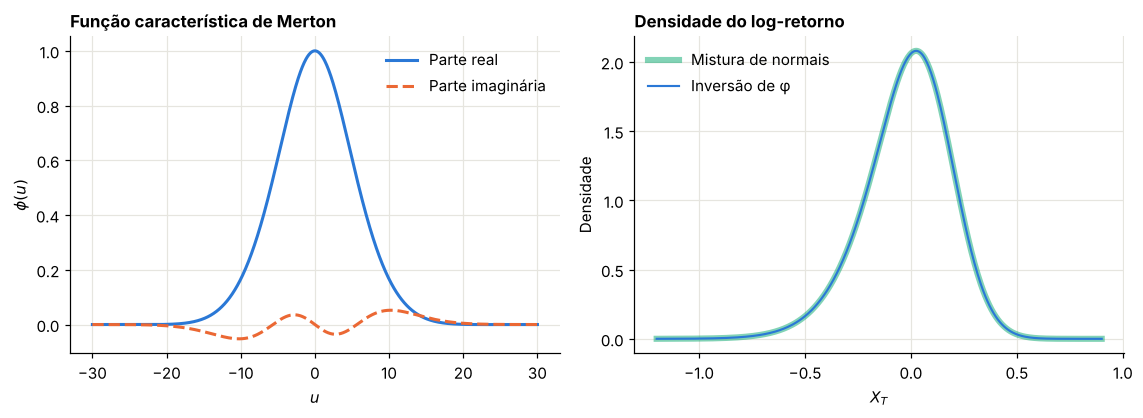

OK — a inversão de φ reproduz a densidade exata


,Cumulante,Da função característica,Fórmula direta
0,c1,"-0,020","-0,020"
1,c2,"0,042","0,042"
2,c3,"-0,004","-0,004"
3,c4,"0,001","0,001"


OK — os cumulantes da função característica batem com as fórmulas


Assimetria teórica: -0,495 | Curtose teórica: 0,621


OK — a variância simulada confere


In [3]:
def cf_bsm(u, T, sigma):
    return np.exp(-0.5 * sigma**2 * T * (1j * u + u**2))


def cf_merton(u, T, sigma, lam, mu, delta):
    omega = -0.5 * sigma**2 - lam * (np.exp(mu + 0.5 * delta**2) - 1)
    return np.exp(T * (1j * u * omega - 0.5 * sigma**2 * u**2 + lam * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1)))


M76 = dict(sigma=0.15, lam=0.8, mu=-0.12, delta=0.10)
T1 = 1.0
ok(abs(cf_merton(0.0, T1, **M76) - 1) < 1e-14, "φ(0) = 1")
ok(abs(cf_merton(-1j, T1, **M76) - 1) < 1e-14, "condição de martingale: φ(−i) = 1")
ok(abs(cf_bsm(-1j, T1, 0.2) - 1) < 1e-14, "condição de martingale para o BSM")

xg = np.linspace(-1.2, 0.9, 421)
ug = np.linspace(-120, 120, 48001)
fi = cf_merton(ug, T1, **M76)
dens_cf = np.array([simpson((np.exp(-1j * ug * x_) * fi).real, x=ug) for x_ in xg]) / (2 * np.pi)

omega = -0.5 * M76["sigma"] ** 2 - M76["lam"] * (np.exp(M76["mu"] + 0.5 * M76["delta"] ** 2) - 1)
dens_mix = np.zeros_like(xg)
for n in range(40):
    dens_mix += poisson.pmf(n, M76["lam"] * T1) * norm.pdf(xg, omega * T1 + n * M76["mu"], np.sqrt(M76["sigma"] ** 2 * T1 + n * M76["delta"] ** 2))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9))
ur = np.linspace(-30, 30, 1201)
fi_r = cf_merton(ur, T1, **M76)
a1.plot(ur, fi_r.real, color=AZUL, label="Parte real")
a1.plot(ur, fi_r.imag, color=LARANJA, ls="--", label="Parte imaginária")
a1.set_title("Função característica de Merton")
a1.set_xlabel("$u$")
a1.set_ylabel("$\\phi(u)$")
a1.legend()
a2.plot(xg, dens_mix, color=VERDE, lw=4, alpha=0.55, label="Mistura de normais")
a2.plot(xg, dens_cf, color=AZUL, lw=1.4, label="Inversão de φ")
a2.set_title("Densidade do log-retorno")
a2.set_xlabel("$X_T$")
a2.set_ylabel("Densidade")
a2.legend()
plt.tight_layout()
plt.show()
ok(np.max(np.abs(dens_cf - dens_mix)) < 1e-8, "a inversão de φ reproduz a densidade exata")


def cumulantes(cf, n_max=4):
    """Derivadas do logaritmo de E[exp(tX)] em t = 0, por mpmath com alta precisão."""
    mp.mp.dps = 40
    psi = lambda t: mp.log(cf(t))
    return [float(mp.diff(psi, 0, n)) for n in range(1, n_max + 1)]


def mgf_merton(t, T=T1, sigma=M76["sigma"], lam=M76["lam"], mu=M76["mu"], delta=M76["delta"]):
    omega = -sigma**2 / 2 - lam * (mp.e ** (mu + delta**2 / 2) - 1)
    return mp.e ** (T * (omega * t + sigma**2 * t**2 / 2 + lam * (mp.e ** (mu * t + delta**2 * t**2 / 2) - 1)))


c1, c2, c3, c4 = cumulantes(mgf_merton)
s, l_, m_, d_ = M76["sigma"], M76["lam"], M76["mu"], M76["delta"]
teoria = [omega * T1 + l_ * m_ * T1, (s**2 + l_ * (m_**2 + d_**2)) * T1, l_ * T1 * (m_**3 + 3 * m_ * d_**2), l_ * T1 * (m_**4 + 6 * m_**2 * d_**2 + 3 * d_**4)]
tabela(pd.DataFrame({"Cumulante": ["c1", "c2", "c3", "c4"], "Da função característica": [c1, c2, c3, c4], "Fórmula direta": teoria}))
ok(np.allclose([c1, c2, c3, c4], teoria, rtol=1e-10), "os cumulantes da função característica batem com as fórmulas")

rng = np.random.default_rng(801)
N = rng.poisson(l_ * T1, 3_000_000)
X_ = omega * T1 + s * np.sqrt(T1) * rng.standard_normal(N.size) + N * m_ + np.sqrt(N) * d_ * rng.standard_normal(N.size)
print("Assimetria teórica:", f3(c3 / c2**1.5), "| Curtose teórica:", f3(c4 / c2**2))
ok(abs(np.var(X_) - c2) < 2e-4, "a variância simulada confere")

---
## 3. A fórmula de Lewis, passo a passo

**Livro: §6.4.1**

### Passo 1: transformar o payoff

Com $s = \ln S_T$, o payoff é $C_T(s) = \max(e^s - K, 0)$. Note um problema: **ele não é integrável**, pois cresce sem limite. A transformada só existe se $u$ tiver parte imaginária suficientemente grande, que produz um amortecimento.

Seja $u = u_r + iu_i$. Como $|e^{ius}| = e^{-u_is}$, a integral converge em $s \to +\infty$ se $u_i > 1$. Calculando:

$$\hat C_T(u) = \int_{\ln K}^\infty e^{ius}(e^s - K)\,ds = \Big[\frac{e^{(iu+1)s}}{iu+1} - K\frac{e^{ius}}{iu}\Big]_{\ln K}^\infty.$$

Com $u_i > 1$, o limite superior é zero. No limite inferior, $e^{(iu+1)\ln K} = K^{iu+1}$ e $K\,e^{iu\ln K} = K^{iu+1}$:

$$\hat C_T(u) = K^{iu+1}\Big(\frac{1}{iu} - \frac{1}{iu+1}\Big) = \frac{K^{iu+1}}{iu(iu+1)} = -\frac{K^{iu+1}}{u^2 - iu}.$$

### Passo 2: inverter e trocar a ordem

Escrevemos o payoff pela inversão, numa reta com $u_i > 1$, e aplicamos a esperança:

$$C_0 = e^{-rT}\,\mathbb{E}^Q\Big[\frac{1}{2\pi}\int e^{-ius}\hat C_T(u)\,du\Big] = \frac{e^{-rT}}{2\pi}\int\mathbb{E}^Q\big[e^{-ius}\big]\hat C_T(u)\,du.$$

### Passo 3: colocar a função característica

Como $s = \ln S_T = y + X_T$, com $y = \ln S_0 + rT$:

$$\mathbb{E}^Q[e^{-ius}] = e^{-iuy}\,\phi(-u).$$

Com $k = \ln(S_0/K) + rT$, juntamos $K^{iu}$ com $e^{-iuy}$, ficando $e^{-iuk}$:

$$\boxed{C_0 = -\frac{Ke^{-rT}}{2\pi}\int_{-\infty+iu_i}^{\infty+iu_i}e^{-iuk}\,\phi(-u)\,\frac{du}{u^2 - iu}, \qquad u_i > 1.}$$

### Passo 4: atravessar um polo

O denominador é $u^2 - iu = u(u-i)$: há polos em $u = 0$ e $u = i$. A reta original está acima de ambos. Queremos descer para $0 < u_i < 1$, onde $\phi(u - i/2)$ é melhor comportada.

O **teorema dos resíduos** diz que, ao mover a reta através de um polo, a integral muda de $2\pi i$ vezes o resíduo. O resíduo em $u = i$ é

$$\text{Res}(i) = \lim_{u\to i}(u-i)\Big[-\frac{Ke^{-rT}}{2\pi}\frac{e^{-iuk}\phi(-u)}{u(u-i)}\Big] = -\frac{Ke^{-rT}}{2\pi}\cdot\frac{e^{k}\,\phi(-i)}{i}.$$

Usando $e^k = (S_0/K)e^{rT}$, $\phi(-i) = 1$ (martingale!) e $1/i = -i$, sobra $\text{Res}(i) = \dfrac{iS_0}{2\pi}$.

A integral em $u_i > 1$ é a integral em $u_i \in (0,1)$ menos $2\pi i\,\text{Res}(i) = -S_0$. Portanto,

$$\boxed{C_0 = S_0 - \frac{Ke^{-rT}}{2\pi}\int_{-\infty+iu_i}^{\infty+iu_i}e^{-iuk}\,\phi(-u)\,\frac{du}{u^2 - iu}, \qquad 0 < u_i < 1.}$$

O termo $S_0$ aparece por causa da condição de martingale. É um bom sinal: é a parte que vem de $\phi(-i) = 1$.

### Passo 5: escolher a reta simétrica

Tomamos $u_i = \tfrac12$, ou seja, $u = z + i/2$, com $z$ real. Calculemos o denominador:

$$(z + \tfrac{i}{2})^2 - i(z + \tfrac{i}{2}) = z^2 + iz - \tfrac14 - iz + \tfrac12 = z^2 + \tfrac14.$$

Um real positivo. O fator exponencial é $e^{-i(z + i/2)k} = e^{-izk}e^{k/2}$, e

$$Ke^{-rT}e^{k/2} = Ke^{-rT}\sqrt{\frac{S_0}{K}}e^{rT/2} = \sqrt{S_0K}\,e^{-rT/2}.$$

Portanto,

$$C_0 = S_0 - \frac{\sqrt{S_0K}\,e^{-rT/2}}{2\pi}\int_{-\infty}^{\infty}e^{-izk}\,\phi(-z - i/2)\,\frac{dz}{z^2 + 1/4}.$$

### Passo 6: integrar só em $z > 0$

A integral é de uma função $h(z)$ com $h(-z) = \overline{h(z)}$. Assim, ela é igual a $2\int_0^\infty\text{Re}[h(z)]\,dz$. Trocando $z \to -z$ na expressão, chega-se à **fórmula de Lewis**:

$$\boxed{C_0 = S_0 - \frac{\sqrt{S_0K}\,e^{-rT/2}}{\pi}\int_0^\infty\text{Re}\big[e^{izk}\,\phi(z - i/2)\big]\frac{dz}{z^2 + 1/4}.}$$

> **Errata do livro.** Na prova da Proposição 6, o livro escreve $(z - i/2)^2 - (z - i/2)i = z^2 - 2zi + 1/4$, e usa esse denominador na equação seguinte. Há dois erros: a substituição deveria ser na variável real, com $u + i/2$, e o resultado da expressão impressa nem é o indicado (daria $z^2 - 2iz - 3/4$). A conta correta é a do Passo 5, e a equação final (6.5) está certa.

### Caso BSM: a integral é real

Com $u = z - i/2$: $iu + u^2 = iz + \tfrac12 + z^2 - iz - \tfrac14 = z^2 + \tfrac14$. Logo, $\phi^{BSM}(z - i/2) = e^{-\frac12\sigma^2T(z^2 + 1/4)}$, um número **real**, e a fórmula de Lewis fica uma integral de $\cos(zk)$ contra uma gaussiana amortecida. O integrando em BSM decai de forma gaussiana, e essa velocidade depende de $\sigma^2T$.

### Laboratório 3.1 — Conferindo a transformada do payoff

In [4]:
K = 2.0
s_g = np.linspace(np.log(K), np.log(K) + 90, 1_800_001)
linhas = []
for u in [0.5 + 1.5j, 2.0 + 2.0j, -3.0 + 1.2j, 7.0 + 3.0j]:
    num = simpson(np.exp(1j * u * s_g) * (np.exp(s_g) - K), x=s_g)
    fec = -(K ** (1j * u + 1)) / (u**2 - 1j * u)
    linhas.append({"u": str(u), "Numérica (real)": num.real, "Fechada (real)": fec.real, "Numérica (imag)": num.imag, "Fechada (imag)": fec.imag, "Erro relativo (×10⁶)": abs(num - fec) / abs(fec) * 1e6})
pt = pd.DataFrame(linhas)
tabela(pt)
ok((pt["Erro relativo (×10⁶)"] < 1).all(), "a transformada do payoff confere numericamente, com u_i > 1")

,u,Numérica (real),Fechada (real),Numérica (imag),Fechada (imag),Erro relativo (×10⁶)
0,(0.5+1.5j),"0,074","0,074","0,628","0,628","0,000"
1,(2+2j),"-0,078","-0,078","-0,011","-0,011","0,000"
2,(-3+1.2j),"0,006","0,006","0,089","0,089","0,049"
3,(7+3j),"0,002","0,002","0,004","0,004","0,000"


OK — a transformada do payoff confere numericamente, com u_i > 1


### Laboratório 3.2 — Mover a reta muda o resultado de forma exata

Calculamos a integral em retas diferentes. O teorema dos resíduos prevê:

- $u_i > 1$: a integral dá a **call**, sem o termo $S_0$;
- $0 < u_i < 1$: a integral mais $S_0$ dá a call;
- $u_i < 0$: a reta passou também pelo polo em $u = 0$, e a integral dá a **put**.

,u_i,Regra,Resultado,Referência BSM,Erro
0,"2,500",Integral = call,"12,757","12,757","0,000"
1,"1,500",Integral = call,"12,757","12,757","0,000"
2,"0,750",S0 + integral = call,"12,757","12,757","0,000"
3,"0,500",S0 + integral = call,"12,757","12,757","0,000"
4,"0,250",S0 + integral = call,"12,757","12,757","0,000"
5,"-0,500",Integral = put,"4,032","4,032","0,000"
6,"-1,500",Integral = put,"4,032","4,032","0,000"


OK — o teorema dos resíduos prevê exatamente o valor em cada faixa


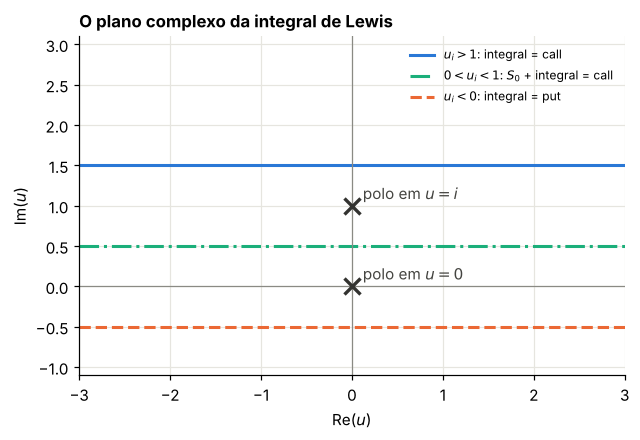

In [5]:
def integral_reta(S, K, T, r, cf, ui, U=300.0, n=120001):
    """Calcula -K exp(-rT)/(2π) ∫ exp(-iuk) φ(-u)/(u²-iu) du em u = z + i·ui."""
    k = np.log(S / K) + r * T
    z = np.linspace(-U, U, n)
    u = z + 1j * ui
    h = np.exp(-1j * u * k) * cf(-u) / (u**2 - 1j * u)
    return float((-K * np.exp(-r * T) / (2 * np.pi) * simpson(h, x=z)).real)


S0, K0, T0, r0, s0 = 100.0, 95.0, 1.0, 0.04, 0.2
cf_b = lambda u: cf_bsm(u, T0, s0)
C_ref, P_ref = float(bsm(S0, K0, T0, r0, s0)), float(bsm(S0, K0, T0, r0, s0, "put"))

linhas = []
for ui in [2.5, 1.5, 0.75, 0.5, 0.25, -0.5, -1.5]:
    I = integral_reta(S0, K0, T0, r0, cf_b, ui)
    if ui > 1:
        prev, nome, ref = I, "Integral = call", C_ref
    elif ui > 0:
        prev, nome, ref = I + S0, "S0 + integral = call", C_ref
    else:
        prev, nome, ref = I, "Integral = put", P_ref
    linhas.append({"u_i": ui, "Regra": nome, "Resultado": prev, "Referência BSM": ref, "Erro": abs(prev - ref)})
ret = pd.DataFrame(linhas)
tabela(ret)
ok((ret["Erro"] < 1e-8).all(), "o teorema dos resíduos prevê exatamente o valor em cada faixa")

fig, ax = plt.subplots(figsize=(6.4, 4.0))
for ui, rot, cor, est in [(1.5, "$u_i > 1$: integral = call", AZUL, "-"), (0.5, "$0 < u_i < 1$: $S_0$ + integral = call", VERDE, "-."), (-0.5, "$u_i < 0$: integral = put", LARANJA, "--")]:
    ax.plot([-3, 3], [ui, ui], color=cor, ls=est, label=rot)
ax.scatter([0, 0], [0, 1], marker="x", s=110, color="#333330", linewidths=2.2, zorder=4)
ax.text(0.12, 1.08, "polo em $u = i$", color="#444440")
ax.text(0.12, 0.08, "polo em $u = 0$", color="#444440")
ax.axhline(0, color=CINZA, lw=0.8)
ax.axvline(0, color=CINZA, lw=0.8)
ax.set_xlim(-3, 3)
ax.set_ylim(-1.1, 3.1)
ax.set_title("O plano complexo da integral de Lewis")
ax.set_xlabel("Re($u$)")
ax.set_ylabel("Im($u$)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

---
## 4. Avaliando a integral

**Livro: §6.4.1, final**

Na prática, resta escolher: até onde integrar, e com que malha.

### 4.1 O integrando

Para BSM: $h(z) = \cos(zk)\,e^{-\frac12\sigma^2T(z^2+1/4)}/(z^2 + 1/4)$. O decaimento é regido pela combinação $\sigma^2T$, ou seja, a variância total. Para **prazos curtos**, a densidade em $x$ é estreita, e a transformada em $z$ é larga: é preciso integrar mais longe.

Uma regra simples para truncar em BSM: queremos $e^{-\frac12\sigma^2TU^2} \le \varepsilon$, ou seja,

$$U \approx \frac{1}{\sigma\sqrt T}\sqrt{2\ln(1/\varepsilon)}.$$

Para modelos com saltos, a parte de difusão ainda é quem garante o decaimento rápido.

### Laboratório 4.1 — O integrando e os limites

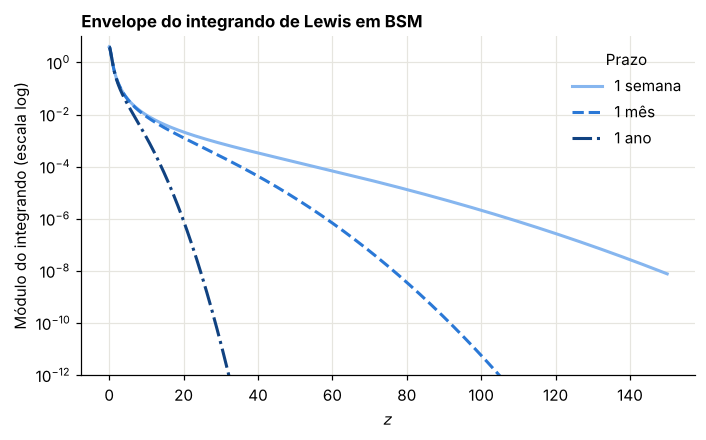

,Prazo,Menor U com erro < 10⁻⁶ (grade de 2ⁿ),Regra 1/(σ√T)·√(2·ln(10⁶))
0,1 semana,"256,000","189,527"
1,1 mês,"128,000","91,046"
2,6 meses,"64,000","37,169"
3,1 ano,"32,000","26,283"
4,2 anos,"32,000","18,585"


OK — prazos menores exigem limites de integração maiores
OK — a regra de truncamento indica a ordem de grandeza correta


In [6]:
def lewis(S, K, T, r, cf, U=None, n=None):
    """Fórmula de Lewis vetorial em K. cf é a função característica de X_T (martingale)."""
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(S / K) + r * T
    z = np.linspace(0.0, U, n)
    h = np.exp(1j * z * k[:, None]) * cf(z - 0.5j)
    integral = simpson(h.real / (z**2 + 0.25), x=z, axis=1)
    return S - np.sqrt(S * K) * np.exp(-0.5 * r * T) / np.pi * integral


fig, ax = plt.subplots()
z = np.linspace(0, 150, 3001)
for T_, cor, est, rot in zip([1 / 52, 1 / 12, 1.0], RAMPA, ["-", "--", "-."], ["1 semana", "1 mês", "1 ano"]):
    ax.semilogy(z, np.exp(-0.5 * 0.2**2 * T_ * (z**2 + 0.25)) / (z**2 + 0.25), color=cor, ls=est, label=rot)
ax.set_ylim(1e-12, 10)
ax.set_title("Envelope do integrando de Lewis em BSM")
ax.set_xlabel("$z$")
ax.set_ylabel("Módulo do integrando (escala log)")
ax.legend(title="Prazo")
plt.show()

K_t = np.array([85.0, 100.0, 115.0])
linhas = []
for rot, T_ in [("1 semana", 1 / 52), ("1 mês", 1 / 12), ("6 meses", 0.5), ("1 ano", 1.0), ("2 anos", 2.0)]:
    ref = bsm(100.0, K_t, T_, 0.04, 0.2)
    cf_ = lambda u: cf_bsm(u, T_, 0.2)
    U_min = None
    for U in 2.0 ** np.arange(1, 13):
        v = lewis(100.0, K_t, T_, 0.04, cf_, U=U, n=max(int(U * 20) * 2 + 1, 4001))
        if np.max(np.abs(v - ref)) < 1e-6:
            U_min = U
            break
    linhas.append({"Prazo": rot, "Menor U com erro < 10⁻⁶ (grade de 2ⁿ)": float(U_min), "Regra 1/(σ√T)·√(2·ln(10⁶))": float(np.sqrt(2 * np.log(1e6)) / (0.2 * np.sqrt(T_)))})
tu = pd.DataFrame(linhas)
tabela(tu)
ok(tu.iloc[:, 1].is_monotonic_decreasing, "prazos menores exigem limites de integração maiores")
ok((tu.iloc[:, 1] <= 2.1 * tu.iloc[:, 2]).all(), "a regra de truncamento indica a ordem de grandeza correta")

### Laboratório 4.2 — Velocidade e precisão, com vários modelos

Aplicamos a mesma função a BSM, Merton e Heston com saltos (a função característica deste último é a do Módulo 2, e será deduzida no Módulo 11). Conferimos com referências independentes: BSM, a série de Merton e Monte Carlo. Em seguida, comparamos custos para 1.000 opções.

In [7]:
def merton_serie(S, K, T, r, sigma, lam, mu, delta, n_max=60):
    """Série de Poisson do Módulo 1, referência independente."""
    kap = np.exp(mu + 0.5 * delta**2) - 1
    lq = lam * (1 + kap)
    tot = 0.0
    for n in range(n_max):
        sn = np.sqrt(sigma**2 + n * delta**2 / T)
        rn = r - lam * kap + n * np.log1p(kap) / T
        tot = tot + poisson.pmf(n, lq * T) * bsm(S, K, T, rn, sn)
    return tot


def cf_bates(u, T, v0, kappa, theta, nu, rho, lam, mu, delta):
    comp = lam * (np.exp(mu + 0.5 * delta**2) - 1)
    salto = np.exp(lam * T * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1))
    deriva = np.exp(-1j * u * comp * T)
    xi = kappa - rho * nu * 1j * u
    d = np.sqrt(xi**2 + nu**2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = kappa * theta / nu**2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / nu**2 * (1 - e) / (1 - g * e)
    return deriva * salto * np.exp(A + B * v0)


S_, r_, T_ = 100.0, 0.03, 0.5
K_m = np.array([70.0, 85.0, 100.0, 115.0, 130.0])
cf_m = lambda u: cf_merton(u, T_, **M76)
v_lw = lewis(S_, K_m, T_, r_, cf_m, U=250.0, n=20001)
v_sr = merton_serie(S_, K_m, T_, r_, **M76)
tabela(pd.DataFrame({"Strike": K_m, "Lewis": v_lw, "Série de Poisson": v_sr, "Diferença (×10⁶)": (v_lw - v_sr) * 1e6}))
ok(np.max(np.abs(v_lw - v_sr)) < 1e-7, "Lewis coincide com a série de Merton")

B97 = dict(v0=0.04, kappa=2.0, theta=0.04, nu=0.4, rho=-0.6, lam=0.5, mu=-0.1, delta=0.1)
ok(abs(cf_bates(-1j, 1.0, **B97) - 1) < 1e-12, "martingale em Heston com saltos: φ(−i) = 1")

rng = np.random.default_rng(802)
n_p, passos = 400_000, 250
dt = T_ / passos
comp = B97["lam"] * (np.exp(B97["mu"] + 0.5 * B97["delta"] ** 2) - 1)
v, x_ = np.full(n_p, B97["v0"]), np.zeros(n_p)
for _ in range(passos):
    z1 = rng.standard_normal(n_p)
    z2 = B97["rho"] * z1 + np.sqrt(1 - B97["rho"] ** 2) * rng.standard_normal(n_p)
    vp = np.maximum(v, 0)
    nj = rng.poisson(B97["lam"] * dt, n_p)
    x_ += (r_ - comp - 0.5 * vp) * dt + np.sqrt(vp * dt) * z1 + nj * B97["mu"] + np.sqrt(nj) * B97["delta"] * rng.standard_normal(n_p)
    v += B97["kappa"] * (B97["theta"] - vp) * dt + B97["nu"] * np.sqrt(vp * dt) * z2
ST = S_ * np.exp(x_)

cf_h = lambda u: cf_bates(u, T_, **B97)
v_h = lewis(S_, K_m, T_, r_, cf_h, U=250.0, n=20001)
linhas = []
for k_, vv in zip(K_m, v_h):
    a = np.exp(-r_ * T_) * np.maximum(ST - k_, 0)
    linhas.append({"Strike": k_, "Lewis": float(vv), "Monte Carlo": float(a.mean()), "Erro-padrão": float(a.std(ddof=1) / np.sqrt(n_p)), "Distância em erros-padrão": float((a.mean() - vv) / (a.std(ddof=1) / np.sqrt(n_p)))})
h_ = pd.DataFrame(linhas)
tabela(h_)
ok((h_["Distância em erros-padrão"].abs() < 4).all(), "Lewis confere com Monte Carlo em Heston com saltos")

K_mil = np.linspace(60, 140, 1000)
t0 = perf_counter(); lewis(S_, K_mil, T_, r_, cf_h, U=200.0, n=4001); t_vet = perf_counter() - t0


def lewis_quad(K):
    k = np.log(S_ / K) + r_ * T_
    f = lambda z: (np.exp(1j * z * k) * cf_h(z - 0.5j)).real / (z**2 + 0.25)
    return S_ - np.sqrt(S_ * K) * np.exp(-0.5 * r_ * T_) / np.pi * quad(f, 0, 200, limit=200)[0]


t0 = perf_counter(); [lewis_quad(k) for k in K_mil[:20]]; t_quad = (perf_counter() - t0) * 50

t0 = perf_counter()
a = np.exp(-r_ * T_) * np.maximum(ST - K_mil[:50, None], 0.0).mean(axis=1)
t_mc = (perf_counter() - t0) * 20

tabela(pd.DataFrame({"Método para 1.000 opções": ["Lewis vetorial", "Lewis com quad adaptativo (extrapolado)", "Monte Carlo com trajetórias prontas: só o cálculo dos payoffs (extrapolado)"], "Tempo (ms)": [t_vet * 1e3, t_quad * 1e3, t_mc * 1e3]}))
ok(t_vet < t_quad, "a versão vetorial é bem mais rápida que a integração adaptativa opção a opção")

,Strike,Lewis,Série de Poisson,Diferença (×10⁶)
0,"70,000","31,151","31,151","0,000"
1,"85,000","17,220","17,220","-0,000"
2,"100,000","6,247","6,247","-0,000"
3,"115,000","1,165","1,165","0,000"
4,"130,000","0,110","0,110","-0,000"


OK — Lewis coincide com a série de Merton
OK — martingale em Heston com saltos: φ(−i) = 1


,Strike,Lewis,Monte Carlo,Erro-padrão,Distância em erros-padrão
0,"70,000","31,256","31,234","0,023","-0,948"
1,"85,000","17,606","17,589","0,020","-0,848"
2,"100,000","6,803","6,796","0,014","-0,505"
3,"115,000","1,265","1,265","0,006","-0,054"
4,"130,000","0,111","0,111","0,002","-0,023"


OK — Lewis confere com Monte Carlo em Heston com saltos


,Método para 1.000 opções,Tempo (ms)
0,Lewis vetorial,"137,090"
1,Lewis com quad adaptativo (extrapolado),"1.373,611"
2,Monte Carlo com trajetórias prontas: só o cálc...,"1.989,091"


OK — a versão vetorial é bem mais rápida que a integração adaptativa opção a opção


---
## 5. Limites de precisão

A fórmula de Lewis calcula o preço como $S_0$ menos uma grande parcela. Para opções **muito fora do dinheiro**, os dois termos quase se cancelam, e o erro de arredondamento pesa mais no resultado. É um fenômeno clássico de **cancelamento catastrófico**. Numa call, o preço é pequeno; numa put com strike baixo, a paridade agrava o problema.

### Laboratório 5.1 — O preço fica pequeno, o erro não

In [8]:
Ks = np.array([100.0, 110.0, 120.0, 130.0, 140.0, 150.0])
T_o, r_o, sig_o = 1 / 12, 0.03, 0.2
cf_o = lambda u: cf_bsm(u, T_o, sig_o)
v = lewis(100.0, Ks, T_o, r_o, cf_o, U=600.0, n=60001)
v_ruim = lewis(100.0, Ks, T_o, r_o, cf_o, U=60.0, n=2001)
ref = bsm(100.0, Ks, T_o, r_o, sig_o)
pc = pd.DataFrame({"Strike": Ks, "Preço BSM (×10⁶)": ref * 1e6, "Malha fina: erro (×10¹²)": np.abs(v - ref) * 1e12, "Malha fina: erro relativo (%)": np.abs(v - ref) / ref * 100, "Malha grossa: erro relativo (%)": np.abs(v_ruim - ref) / ref * 100})
tabela(pc)
ok(pc["Malha fina: erro (×10¹²)"].max() < 100, "com malha fina, o erro absoluto fica abaixo de 10⁻¹⁰")
ok(pc["Malha grossa: erro relativo (%)"].iloc[-1] > 1 and pc["Malha grossa: erro relativo (%)"].iloc[0] < 1e-2, "com malha grossa, o erro relativo nas caudas é grande, mesmo sendo desprezível no dinheiro")

,Strike,Preço BSM (×10⁶),Malha fina: erro (×10¹²),Malha fina: erro relativo (%),Malha grossa: erro relativo (%)
0,"100,000","2.427.098,631","0,028","0,000","0,004"
1,"110,000","138.045,658","0,004","0,000","0,060"
2,"120,000","1.600,465","0,014","0,000","2,053"
3,"130,000","4,541","0,011","0,000","1.204,908"
4,"140,000","0,004","0,005","0,000","839.225,289"
5,"150,000","0,000","0,006","0,429","4.004.758.061,695"


OK — com malha fina, o erro absoluto fica abaixo de 10⁻¹⁰
OK — com malha grossa, o erro relativo nas caudas é grande, mesmo sendo desprezível no dinheiro


**Leitura.** O erro absoluto é minúsculo em todos os strikes, e é isso que costuma ser observado. Mas o que importa nas caudas é o erro relativo: com uma malha que parece boa para a opção no dinheiro, o preço de uma opção muito fora do dinheiro pode sair sem nenhum dígito correto. Se você calcular uma volatilidade implícita a partir desse preço, o resultado será ruim. O Módulo 8 apresenta a transformada específica para fora do dinheiro.

---
## 6. Gregas pela função característica

Como $\phi$ não depende de $S_0$, derivadas em $S_0$ entram só no prefator e em $k$. Derivando dentro da integral:

$$\frac{\partial}{\partial S_0}\Big[\sqrt{S_0K}\,e^{izk}\Big] = \sqrt{\frac{K}{S_0}}\,e^{izk}\Big(\frac12 + iz\Big).$$

Logo,

$$\Delta = 1 - \frac{1}{\pi}\sqrt{\frac{K}{S_0}}\,e^{-rT/2}\int_0^\infty\text{Re}\Big[e^{izk}\phi(z - i/2)\big(\tfrac12 + iz\big)\Big]\frac{dz}{z^2 + 1/4}.$$

É a **mesma integral**, com um fator a mais. Custo extra quase zero e sem erro de diferenças finitas.

### Laboratório 6.1 — Delta

In [9]:
def delta_lewis(S, K, T, r, cf, U, n):
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(S / K) + r * T
    z = np.linspace(0.0, U, n)
    h = np.exp(1j * z * k[:, None]) * cf(z - 0.5j) * (0.5 + 1j * z)
    integral = simpson(h.real / (z**2 + 0.25), x=z, axis=1)
    return 1 - np.sqrt(K / S) * np.exp(-0.5 * r * T) / np.pi * integral


Kd = np.array([85.0, 100.0, 115.0])
T_d, r_d, s_d = 0.5, 0.03, 0.2
dl = delta_lewis(100.0, Kd, T_d, r_d, lambda u: cf_bsm(u, T_d, s_d), 200.0, 20001)
d1 = (np.log(100.0 / Kd) + (r_d + 0.5 * s_d**2) * T_d) / (s_d * np.sqrt(T_d))
ok(np.max(np.abs(dl - norm.cdf(d1))) < 1e-8, "em BSM, o delta de Lewis é N(d1)")

cf_d = lambda u: cf_bates(u, T_d, **B97)
dl_h = delta_lewis(100.0, Kd, T_d, r_d, cf_d, 300.0, 30001)
h = 0.01
dif = (lewis(100.0 + h, Kd, T_d, r_d, cf_d, U=300.0, n=30001) - lewis(100.0 - h, Kd, T_d, r_d, cf_d, U=300.0, n=30001)) / (2 * h)
tabela(pd.DataFrame({"Strike": Kd, "Delta integral": dl_h, "Delta por diferenças finitas": dif}))
ok(np.max(np.abs(dl_h - dif)) < 1e-6, "em Heston com saltos, o delta integral coincide com o de diferenças finitas")

OK — em BSM, o delta de Lewis é N(d1)


,Strike,Delta integral,Delta por diferenças finitas
0,"85,000","0,893","0,893"
1,"100,000","0,634","0,634"
2,"115,000","0,220","0,220"


OK — em Heston com saltos, o delta integral coincide com o de diferenças finitas


---
## 7. Síntese

- A transformada converte convoluções em produtos. Por isso, $\phi$ é simples mesmo quando a densidade não é.
- $\phi(-i) = 1$ é a condição de martingale.
- A fórmula de Lewis tem três ingredientes: transformada do payoff em $u_i > 1$, Parseval/Fubini e um resíduo em $u = i$.
- Mover a reta troca call, call menos $S_0$ e put, exatamente como o teorema dos resíduos prevê.
- Prazos curtos exigem integrar mais longe.
- Nas caudas, o erro relativo domina.
- O delta sai da mesma integral.

## 8. Notas sobre o livro neste trecho

| Local | Comentário |
|---|---|
| Prova da Prop. 6 | a expressão $(z - i/2)^2 - (z - i/2)i = z^2 - 2zi + 1/4$ está errada; o denominador correto, com a reta em $u_i = 1/2$, é $z^2 + 1/4$. A fórmula (6.5) está certa |
| Geral | a existência de $\phi$ em argumentos complexos exige uma faixa de analiticidade, que o texto não discute |

## 9. Exercícios

**Exercício 1.** Mostre que, para $Y = aX + b$, a função característica é $\phi_Y(u) = e^{iub}\phi_X(au)$.

<details><summary>Solução</summary>

$\mathbb{E}[e^{iu(aX+b)}] = e^{iub}\,\mathbb{E}[e^{i(au)X}] = e^{iub}\phi_X(au)$.
</details>

**Exercício 2.** Use a relação do Exercício 1 e a função $e^{-u^2/2}$ para obter a função característica de $N(\mu, \sigma^2)$.

<details><summary>Solução</summary>

$\phi(u) = e^{iu\mu - \sigma^2u^2/2}$.
</details>

**Exercício 3.** Calcule a curtose em excesso de $X_T$ no Merton, em função de $T$, e explique o achatamento do smile com o prazo.

<details><summary>Solução</summary>

$c_4/c_2^2 = \lambda T\,m_4/\big[T(\sigma^2 + \lambda m_2)\big]^2 = \dfrac{\lambda m_4}{T(\sigma^2 + \lambda m_2)^2}$, com $m_2 = \mu_J^2 + \delta^2$ e $m_4 = \mu_J^4 + 6\mu_J^2\delta^2 + 3\delta^4$. Cai com $1/T$: em prazos longos, a distribuição se aproxima da normal.
</details>

**Exercício 4.** Por que a escolha $u_i = 1/2$ é natural para a fórmula de Lewis?

<details><summary>Solução</summary>

É o meio da faixa entre os polos $u = 0$ e $u = i$. O denominador vira o número real positivo $z^2 + 1/4$, e o integrando fica afastado dos dois polos, o que beneficia a integração numérica.
</details>

**Exercício 5.** Derive, da mesma forma que o delta, uma integral para o gama.

<details><summary>Solução</summary>

Derivando de novo: $\dfrac{\partial}{\partial S_0}\big[\sqrt{K/S_0}\,e^{izk}(\tfrac12 + iz)\big] = \sqrt{K}\,S_0^{-3/2}\,e^{izk}\,(\tfrac12 + iz)(iz - \tfrac12)$, e $(\tfrac12 + iz)(iz - \tfrac12) = -(z^2 + \tfrac14)$. O denominador se cancela: $\Gamma = \dfrac{\sqrt K\,e^{-rT/2}}{\pi S_0^{3/2}}\displaystyle\int_0^\infty\text{Re}\big[e^{izk}\phi(z - i/2)\big]\,dz$.
</details>

In [10]:
print(f"Módulo 7 concluído: {_checks['n']} verificações aprovadas.")

Módulo 7 concluído: 22 verificações aprovadas.
